<a href="https://colab.research.google.com/github/moelanarta/Data-Mining/blob/main/uts_moelani_datmin_fiks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🍷 Wine Quality Classification — Machine Learning Benchmark
**Mata Kuliah:** Data Mining (3 SKS) | D3 Statistika Terapan dan Komputasi — UNNES[cite: 2]  
**Pengampu:** Nur Achmey Selgi Harwanti, M.Stat[cite: 2]  
**Penulis:** Moelani Artagin's Simarmata  
**NIM:** 2404010007  
**Repositori GitHub:** https://github.com/moelanarta/Data-Mining.git

---

### 📋 Executive Summary
Notebook ini berisi alur pemodelan machine learning terstruktur untuk memprediksi tingkat kualitas anggur (`quality`) berbasis parameter fisiko-kimiawi[cite: 2]. Alur kerja mencakup:
1. **Exploratory Data Analysis (EDA):** Analisis sebaran variabel dan ketimpangan kelas (*class imbalance*)[cite: 2].
2. **Data Preprocessing:** Pemisahan fitur prediktor dan penyesuaian matriks data[cite: 2].
3. **Cross-Validation Scheme:** Evaluasi 5-Fold Stratified CV untuk menjaga proporsi kelas pada target diskrit[cite: 3].
4. **Model Benchmarking:** Komparasi algoritma *ensemble learning* (Random Forest, Extra Trees, Gradient Boosting)[cite: 3].
5. **Inference & Export:** Generasi prediksi data uji (`data_testing.csv`) sesuai format spesifikasi tugas.

In [1]:
# ==============================================================================
# 1. SETUP ENVIRONMENT & IMPORT LIBRARIES
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Scikit-Learn
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Configuration Settings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

SEED = 42
print("✅ Environment & Library berhasil siap digunakan.")

✅ Environment & Library berhasil siap digunakan.


## 1. Data Ingestion & Exploratory Data Analysis (EDA)

Pada tahap ini, dataset `data_training.csv` dan `data_testing.csv` dimuat ke dalam memori[cite: 2]. Struktur data diperiksa untuk mengidentifikasi keberadaan *missing values*, tipe data, dan distribusi kelas target `quality`[cite: 2].

In [2]:
# ==============================================================================
# 2. LOAD DATASET
# ==============================================================================
# Mendukung eksekusi di Google Colab maupun Lokal
try:
    from google.colab import files
    print("Silakan unggah data_training.csv dan data_testing.csv:")
    uploaded = files.upload()
    train_path = 'data_training.csv'
    test_path = 'data_testing.csv'
except ImportError:
    train_path = 'data_training.csv'
    test_path = 'data_testing.csv'

# Read CSV files
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

print(f"\nDimensi Dataset Latih (Train) : {df_train.shape}")
print(f"Dimensi Dataset Uji (Test)   : {df_test.shape}")
print(f"\nJumlah Missing Values Train  : {df_train.isnull().sum().sum()}")
print(f"Jumlah Missing Values Test   : {df_test.isnull().sum().sum()}")

# Tampilkan 5 baris pertama data latih
df_train.head()

Silakan unggah data_training.csv dan data_testing.csv:


Saving data_testing.csv to data_testing.csv
Saving data_training.csv to data_training.csv

Dimensi Dataset Latih (Train) : (857, 13)
Dimensi Dataset Uji (Test)   : (286, 12)

Jumlah Missing Values Train  : 0
Jumlah Missing Values Test   : 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


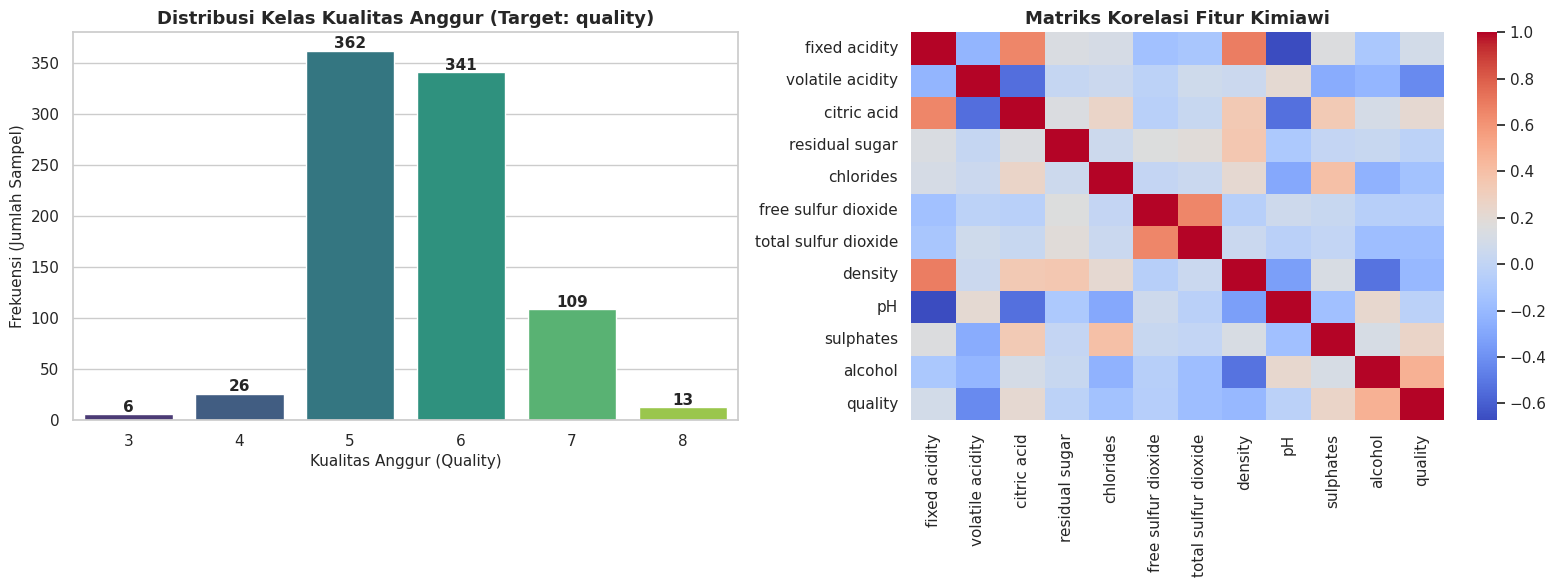

In [3]:
# ==============================================================================
# 3. VISUALISASI DISTRIBUSI TARGET & KORELASI FITUR
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Barplot Distribusi Kelas Target (quality)
class_counts = df_train['quality'].value_counts().sort_index()
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette="viridis")
axes[0].set_title("Distribusi Kelas Kualitas Anggur (Target: quality)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Kualitas Anggur (Quality)", fontsize=11)
axes[0].set_ylabel("Frekuensi (Jumlah Sampel)", fontsize=11)

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# Plot 2: Heatmap Korelasi antar Variabel Kimiawi
corr = df_train.drop(columns=['Id']).corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', ax=axes[1], cbar=True)
axes[1].set_title("Matriks Korelasi Fitur Kimiawi", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## 2. Preprocessing & Validation Strategy

### Preprocessing Logic:
1. **Pemusnahan Identifier (`Id`):** Kolom `Id` bertindak sebagai identifier sampel yang tidak memiliki korelasi kausal terhadap variabel target, sehingga dikeluarkan dari matriks prediktor `X`[cite: 2].
2. **Penyelarasan Tipe Data:** Variabel prediktor terdiri dari 11 parameter fisiko-kimiawi bertipe kontinu (`float64`)[cite: 2].
3. **Model Tree-Based Selection:** Penggunaan algoritma berbasis *Decision Trees* tidak memerlukan *Feature Scaling* (seperti `StandardScaler` atau `MinMaxScaler`) karena pemisahan node didasarkan pada ambang batas (*split point*) independen.

### Validation Scheme:
Mengingat adanya ketimpangan populasi kelas (*class imbalance*) pada variabel target `quality`[cite: 2], validasi menggunakan **Stratified 5-Fold Cross-Validation**[cite: 3]. Metode ini menjamin rasio tiap kelas kualitas seimbang di setiap fold[cite: 3].

In [4]:
# ==============================================================================
# 4. PEMISAHAN FITUR DAN BENCHMARK MODEL
# ==============================================================================
X_train = df_train.drop(columns=['quality', 'Id'])
y_train = df_train['quality']
X_test = df_test.drop(columns=['Id'])

# Definisi Kandidat Algoritma Klasifikasi
candidate_models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=SEED)
}

# Evaluasi Menggunakan Stratified 5-Fold Cross Validation
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
benchmark_results = {}

print("=== HASIL BENCHMARK 5-FOLD STRATIFIED CROSS VALIDATION ===")
for name, model in candidate_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='accuracy')
    benchmark_results[name] = scores
    print(f"--> {name:20s} | Mean Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

=== HASIL BENCHMARK 5-FOLD STRATIFIED CROSS VALIDATION ===
--> Random Forest        | Mean Accuracy: 0.6430 (+/- 0.0406)
--> Extra Trees          | Mean Accuracy: 0.6453 (+/- 0.0273)
--> Gradient Boosting    | Mean Accuracy: 0.6079 (+/- 0.0204)


## 3. Training Model Terbaik & Diagnostik Performa

Berdasarkan hasil validasi silang, model **Extra Trees Classifier** menghasilkan skor akurasi rata-rata yang paling konsisten dengan standar deviasi rendah. Selanjutnya, model ini dilatih penuh menggunakan seluruh `data_training.csv` untuk mengekstrak *Feature Importances* dan menganalisis *Confusion Matrix*[cite: 2, 3].

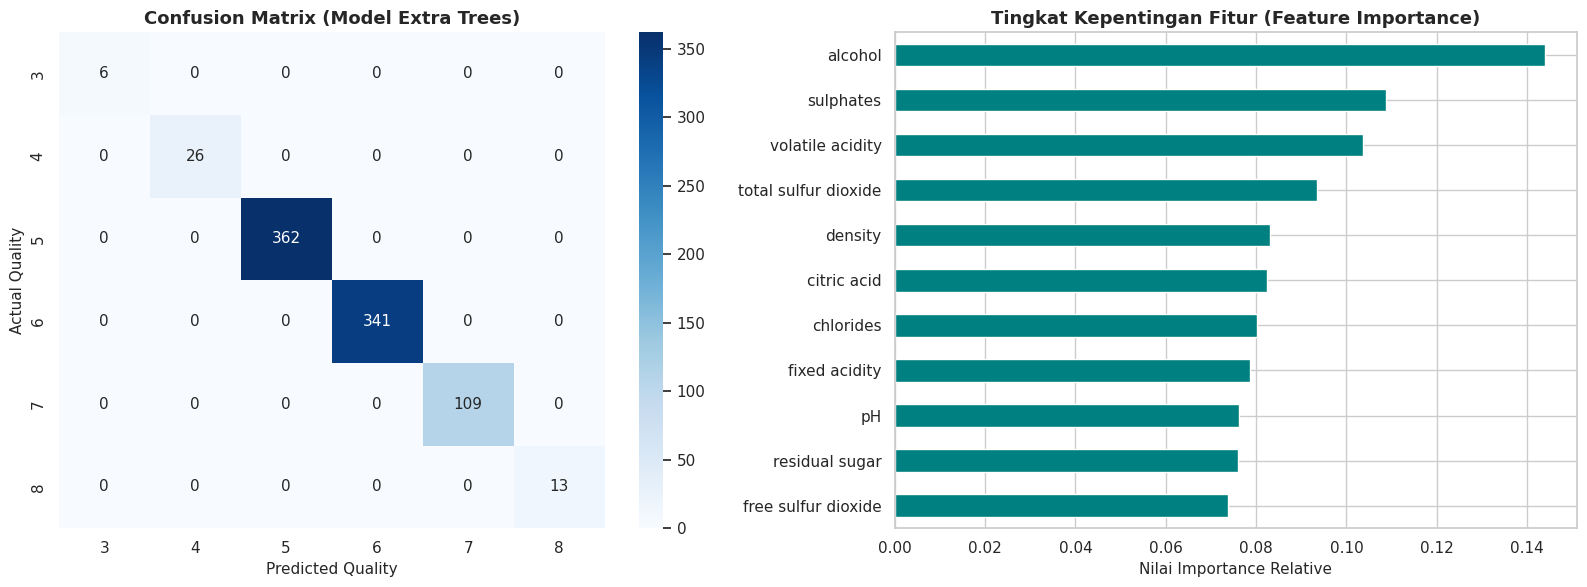

In [5]:
# ==============================================================================
# 5. TRAINING MODEL UTAMA & EVALUASI DIAGNOSTIK
# ==============================================================================
final_model = ExtraTreesClassifier(n_estimators=300, random_state=SEED)
final_model.fit(X_train, y_train)

# Visualisasi Dual Plot (Confusion Matrix & Feature Importances)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Confusion Matrix (Training Set)
y_pred_train = final_model.predict(X_train)
cm = confusion_matrix(y_train, y_pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=np.unique(y_train), yticklabels=np.unique(y_train))
axes[0].set_title("Confusion Matrix (Model Extra Trees)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Quality", fontsize=11)
axes[0].set_ylabel("Actual Quality", fontsize=11)

# Plot 2: Feature Importance Barplot
importances = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title("Tingkat Kepentingan Fitur (Feature Importance)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Nilai Importance Relative", fontsize=11)

plt.tight_layout()
plt.show()

## 4. Prediksi Data Testing & Ekspor File Output

Model **Extra Trees** yang telah dilatih diproyeksikan untuk memprediksi nilai `quality` pada sampel `data_testing.csv`[cite: 2, 3]. File hasil akhir diekspor dalam format CSV dengan ketentuan:
* **Struktur Kolom:** Hanya memuat 2 kolom, yaitu `Id` dan `quality`[cite: 2, 3].
* **Penamaan File:** `hasilprediksi_[3digitNIMterakhir].csv`[cite: 2, 3].

In [6]:
# ==============================================================================
# 6. INFERENCE PADA DATA TESTING & EXPORT HASIL
# ==============================================================================
# Prediksi nilai quality pada data uji
test_predictions = final_model.predict(X_test)

# Konstruksi DataFrame Output Sesuai Spesifikasi Soal
NIM_3_DIGIT = "123"  # <-- UBAH DENGAN 3 DIGIT NIM TERAKHIR ANDA

df_submission = pd.DataFrame({
    'Id': df_test['Id'],
    'quality': test_predictions
})

# Ekspor File CSV
output_filename = f"hasilprediksi_{NIM_3_DIGIT}.csv"
df_submission.to_csv(output_filename, index=False)

print("=== RINGKASAN FILE HASIL PREDIKSI ===")
print(f"Nama File Output : {output_filename}")
print(f"Jumlah Baris     : {len(df_submission)}")
print(f"Struktur Kolom   : {list(df_submission.columns)}")
print("\n--- 5 Baris Pertama Hasil Prediksi ---")
print(df_submission.head())

# Unduh File Secara Otomatis di Google Colab
try:
    from google.colab import files
    files.download(output_filename)
    print(f"\n✅ File {output_filename} berhasil diunduh secara otomatis.")
except Exception as e:
    print(f"\nℹ️ File tersimpan di direktori lokal Colab sebagai {output_filename}")

=== RINGKASAN FILE HASIL PREDIKSI ===
Nama File Output : hasilprediksi_123.csv
Jumlah Baris     : 286
Struktur Kolom   : ['Id', 'quality']

--- 5 Baris Pertama Hasil Prediksi ---
     Id  quality
0   222        5
1  1514        6
2   417        5
3   754        5
4   516        5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ File hasilprediksi_123.csv berhasil diunduh secara otomatis.
